# Transformer XRD
This notebook is adapted from [VIT_Materials_Spectra](https://github.com/linresearchgroup/ViT_Materials_Spectra) and uses vision transformers to classify space groups from XRD data.

- [Data](https://drive.google.com/drive/folders/ANONYMIZED-DATA-FOLDER)
- [Models](https://drive.google.com/drive/folders/ANONYMIZED-MODELS-FOLDER)

Adaptations from standard ViTs:

| Feature           | Standard ViT (Images) | This ViT Model (Spectra) |
|------------------|----------------------|--------------------------|
| Input Data Type  | 2D Images (H × W × C) | 1D Spectral Data (XRD)   |
| Tokenization     | Image patches         | Spectral segments        |
| Patch Embedding  | Linear Projection     | `Spectra_Embedding` function |
| Positional Encoding | Learned            | Learned (`pos_embed`)    |
| Output          | Image classification   | XRD classification/regression |


## Imports

In [1]:
!pip install torchviz --quiet
!pip install torchinfo --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 115.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 89.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 53.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 90.6 MB/s eta 0:00:00


In [2]:
from functools import partial
from netrc import netrc
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Sequential, Linear, ReLU, GRU

from torch.optim import Adam
from torch.nn import CrossEntropyLoss
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
#from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd
import pickle

# Import the library to mount Google Drive
from google.colab import drive

import h5py

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

from torchviz import make_dot
from torchinfo import summary


In [3]:
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


## Global Variables

In [4]:
datasource = "PowCOD"
size = "small"
intensity_points = 500
twotheta = True
space = "2theta"
twotheta_start = 4.0
twotheta_end = 44.0
test_split = 0.20
validation_split = 0.20
num_classes = 230
model_path = '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Models/'
data_path = '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data/'

In [5]:
num_epochs = 10
batch_size = 64
embed_dim=60
depth=12
num_heads=2
mlp_ratio=4.0

In [6]:
if torch.cuda.is_available():
    print("CUDA is available.")
    print("PyTorch version:", torch.__version__)
    print("CUDA version:", torch.version.cuda)
    print("Number of available GPUs:", torch.cuda.device_count())
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available.")

CUDA is available.
PyTorch version: 2.5.1+cu124
CUDA version: 12.4
Number of available GPUs: 1
GPU name: Tesla T4


In [7]:
#with open('....pkl', 'rb') as f:
#    Data = pickle.load(f)

In [8]:
#Reference:https://github.com/chensaian/TransG-Net

## Functions

In [9]:
class EncoderBlock(nn.Module):
    def __init__(self,
                 dim,
                 num_heads,
                 mlp_ratio=4.,
                 qkv_bias=False,
                 qk_scale=None,
                 drop_ratio=0.,
                 attn_drop_ratio=0.,
                 drop_path_ratio=0.,
                 act_layer=nn.GELU,
                 norm_layer=nn.LayerNorm):
        super(EncoderBlock, self).__init__()
        self.norm1 = norm_layer(dim)
        self.attn = Attention(dim, num_heads=num_heads, qkv_bias=qkv_bias, qk_scale=qk_scale,
                              attn_drop_ratio=attn_drop_ratio, proj_drop_ratio=drop_ratio)
        self.drop_path = DropPath(
            drop_path_ratio) if drop_path_ratio > 0. else nn.Identity()
        self.norm2 = norm_layer(dim)
        mlp_hidden_dim = int(dim * mlp_ratio)
        self.mlp = Mlp(in_features=dim, hidden_features=mlp_hidden_dim,
                       act_layer=act_layer, drop=drop_ratio)

    def forward(self, x):
        x = x + self.drop_path(self.attn(self.norm1(x)))
        x = x + self.drop_path(self.mlp(self.norm2(x)))
        return x

In [10]:
class Attention(nn.Module):

    def __init__(self,
                 dim,
                 num_heads=2,
                 qkv_bias=False,
                 qk_scale=None,
                 attn_drop_ratio=0.,
                 proj_drop_ratio=0.):
        super(Attention, self).__init__()
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = qk_scale or head_dim ** -0.5
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop_ratio)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop_ratio)

    def forward(self, x):
        # [batch_size, num_patches + 1, total_embed_dim]
        B, N, C = x.shape
        # qkv(): -> [batch_size, num_patches + 1, 3 * total_embed_dim]
        # reshape: -> [batch_size, num_patches + 1, 3, num_heads, embed_dim_per_head]
        # permute: -> [3, batch_size, num_heads, num_patches + 1, embed_dim_per_head]
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        # [batch_size, num_heads, num_patches + 1, embed_dim_per_head]
        # make torchscript happy (cannot use tensor as tuple)
        q, k, v = qkv[0], qkv[1], qkv[2]
        # transpose: -> [batch_size, num_heads, embed_dim_per_head, num_patches + 1]
        # @: multiply -> [batch_size, num_heads, num_patches + 1, num_patches + 1]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)
        # @: multiply -> [batch_size, num_heads, num_patches + 1, embed_dim_per_head]
        # transpose: -> [batch_size, num_patches + 1, num_heads, embed_dim_per_head]
        # reshape: -> [batch_size, num_patches + 1, total_embed_dim]
        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)
        return x


In [11]:
class Mlp(nn.Module):

    def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = act_layer()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x

In [12]:
import torch.nn.functional as F

def Spectra_Embedding(x, spec_length, embed_dim):
    batch_size = x.shape[0]
    new_spec_length = (spec_length // embed_dim) * embed_dim
    x = x[:, :new_spec_length]
    x = torch.reshape(x, (batch_size, spec_length // embed_dim, embed_dim))
    return x
'''
def Spectra_Embedding_old(x, spec_length, embed_dim):

    batch_size = x.shape[0]
    x = torch.reshape(x, (batch_size, spec_length // embed_dim, embed_dim))
    return x

def Spectra_Embedding_enlong(x, spec_length, embed_dim):
    batch_size = x.shape[0]
    remainder = spec_length % embed_dim
    if remainder != 0:
        pad = embed_dim - remainder
        x = F.pad(x, (0, pad))
    x = torch.reshape(x, (batch_size, -1, embed_dim))
    return x
'''

'\ndef Spectra_Embedding_old(x, spec_length, embed_dim):\n\n    batch_size = x.shape[0]\n    x = torch.reshape(x, (batch_size, spec_length // embed_dim, embed_dim))\n    return x\n\ndef Spectra_Embedding_enlong(x, spec_length, embed_dim):\n    batch_size = x.shape[0]\n    remainder = spec_length % embed_dim\n    if remainder != 0:\n        pad = embed_dim - remainder\n        x = F.pad(x, (0, pad))\n    x = torch.reshape(x, (batch_size, -1, embed_dim))\n    return x\n'

In [13]:
class VIT(nn.Module):
    def __init__(self, spec_length=2000, num_output=1,
                 embed_dim=40, depth=12, num_heads=2, mlp_ratio=4.0, qkv_bias=True,
                 qk_scale=None, drop_ratio=0.,
                 attn_drop_ratio=0., drop_path_ratio=0., norm_layer=None,
                 act_layer=None):

        # MSTransformer
        super(VIT, self).__init__()
        self.num_classes = num_output
        self.spec_length = spec_length
        self.num_features = self.embed_dim = embed_dim
        norm_layer = norm_layer or partial(nn.LayerNorm, eps=1e-6)
        act_layer = act_layer or nn.GELU
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, (spec_length//embed_dim) + 1, embed_dim))
        self.pos_drop = nn.Dropout(p=drop_ratio)
        dpr = [x.item() for x in torch.linspace(0, drop_path_ratio, depth)]
        self.blocks = nn.Sequential(*[
            EncoderBlock(dim=embed_dim, num_heads=num_heads, mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, qk_scale=qk_scale,
                        drop_ratio=drop_ratio, attn_drop_ratio=attn_drop_ratio, drop_path_ratio=dpr[i],
                        norm_layer=norm_layer, act_layer=act_layer)
            for i in range(depth)
        ])
        self.norm = norm_layer(embed_dim)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(_init_vit_weights)

        self.head = nn.Linear(embed_dim, num_output)

    def forward(self, x):
        # [B , xrd_length] --> [B , xrd_length/embed_dim , embed_dim]
        x = Spectra_Embedding(x, self.spec_length, self.embed_dim)
        cls_token = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat((cls_token, x), dim=1)
        x = self.pos_drop(x + self.pos_embed)
        x = self.blocks(x)
        x = self.norm(x)
        x = self.head(x)

        return x[:, 0]

def _init_vit_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.trunc_normal_(m.weight, std=.01)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.LayerNorm):
        nn.init.zeros_(m.bias)
        nn.init.ones_(m.weight)

def VIT_model(spec_length=2251,num_output: int = 1, embed_dim=40, depth=12, num_heads=2):
    model = VIT(spec_length=spec_length,
                              embed_dim=embed_dim,
                              depth=depth,
                              num_heads=num_heads,
                              num_output=num_output)
    return model


## Data Loader

In [14]:
with h5py.File(f"{data_path}{datasource}_{size}_{intensity_points}_{space}_{twotheta_start}_{twotheta_end}_{test_split}_{validation_split}.h5", "r") as f:
    X_train = f["X_train"][:]
    y_train = f["y_train"][:]
    X_val = f["X_val"][:]
    y_val = f["y_val"][:]
    X_test = f["X_test"][:]
    y_test = f["y_test"][:]

print("Data successfully loaded!")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}, y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")


Data successfully loaded!
X_train shape: (184396, 500), y_train shape: (184396,)
X_val shape: (46100, 500), y_val shape: (46100,)
X_test shape: (57625, 500), y_test shape: (57625,)


In [15]:
# no encoding necessary
#label_encoder = LabelEncoder()
#y = label_encoder.fit_transform(y)


## Training

In [16]:
# Cross entropy loss requires 0 indices

y_train = y_train - 1  # Convert range 1-230 → 0-229
y_test = y_test - 1
y_val = y_val - 1

In [17]:

X_train = torch.tensor(X_train, dtype=torch.float)
y_train = torch.tensor(y_train, dtype=torch.long)
X_test = torch.tensor(X_test, dtype=torch.float)
y_test = torch.tensor(y_test, dtype=torch.long)
X_val = torch.tensor(X_val, dtype=torch.float)
y_val = torch.tensor(y_val, dtype=torch.long)


#batch_size = 64
train_data = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_data = TensorDataset(X_train, y_train)
val_loader = DataLoader(train_data, batch_size=batch_size, shuffle=False)
test_data = TensorDataset(X_test, y_test)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

In [18]:
# num_classes=225
model = VIT_model(spec_length=intensity_points,num_output=num_classes, embed_dim=embed_dim, depth=depth, num_heads=num_heads)
summary(model)

Layer (type:depth-idx)                   Param #
VIT                                      600
├─Dropout: 1-1                           --
├─Sequential: 1-2                        --
│    └─EncoderBlock: 2-1                 --
│    │    └─LayerNorm: 3-1               120
│    │    └─Attention: 3-2               14,640
│    │    └─Identity: 3-3                --
│    │    └─LayerNorm: 3-4               120
│    │    └─Mlp: 3-5                     29,100
│    └─EncoderBlock: 2-2                 --
│    │    └─LayerNorm: 3-6               120
│    │    └─Attention: 3-7               14,640
│    │    └─Identity: 3-8                --
│    │    └─LayerNorm: 3-9               120
│    │    └─Mlp: 3-10                    29,100
│    └─EncoderBlock: 2-3                 --
│    │    └─LayerNorm: 3-11              120
│    │    └─Attention: 3-12              14,640
│    │    └─Identity: 3-13               --
│    │    └─LayerNorm: 3-14              120
│    │    └─Mlp: 3-15                    29,

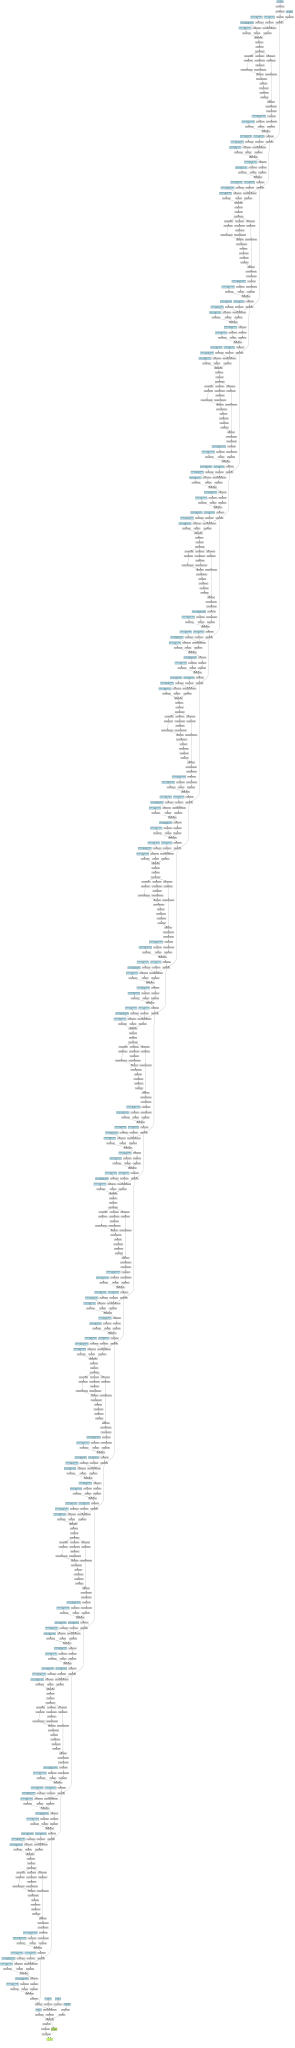

In [19]:
# num_classes=225
# Generate dummy input
x = torch.randn(1, intensity_points)  # Batch size = 1, Sequence length = 2251
# Get only the prediction output (ignore attention maps)
output = model(x)  # model returns (prediction, attention_maps)

dot = make_dot(output, params=dict(model.named_parameters()))
dot.render("vit_model_graph", format="png")  # Saves as 'vit_model_graph.png'
dot

In [20]:
import datetime
import os
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# num_classes=2000
# model = VIT_model(spec_length=2251,num_output=num_classes)

# num_classes=225
model = VIT_model(spec_length=intensity_points,num_output=num_classes, embed_dim=embed_dim, depth=depth, num_heads=num_heads)
# model = VIT_model(spec_length=2251,num_output=num_classes
model = model.to(device)

optimizer = Adam(model.parameters())
loss_func = CrossEntropyLoss()

import matplotlib.pyplot as plt

num_epochs = num_epochs
losses = []
early_stop_loss = 0.98
no_improve_epoch = 0
patience = 3
epoch_times = []
total_time=0
for epoch in range(num_epochs):
    start_time = time.time()
    model.train()
    running_loss = 0.0
    for i, (x_batch, y_batch) in enumerate(train_loader):
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(x_batch)
        loss = loss_func(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    end_time = time.time()
    epoch_duration = end_time - start_time
    epoch_times.append(epoch_duration)
    total_time+=epoch_duration

    epoch_loss = running_loss / len(train_loader)
    print(f'Epoch: {epoch+1}, Loss: {epoch_loss}, Time: {epoch_duration:.2f}s,Total time:{total_time}')

    losses.append(epoch_loss)
    #print(f'Epoch: {epoch+1}, Loss: {epoch_loss}')


    if epoch > 0 and epoch_loss > losses[epoch-1]*early_stop_loss:
        no_improve_epoch += 1
        print(no_improve_epoch)
    else:
        no_improve_epoch = 0

    if no_improve_epoch > patience:
        print("Early stopping!")
        break

current_time = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")



cuda
Epoch: 1, Loss: 2.1818112060893005, Time: 76.41s,Total time:76.40956616401672
Epoch: 2, Loss: 2.054837876107443, Time: 73.97s,Total time:150.374685049057
Epoch: 3, Loss: 1.9809582457618529, Time: 74.75s,Total time:225.12584400177002
Epoch: 4, Loss: 1.9055571003890055, Time: 74.15s,Total time:299.2734920978546
Epoch: 5, Loss: 1.854639516201059, Time: 73.86s,Total time:373.12984251976013
Epoch: 6, Loss: 1.8091008341370318, Time: 72.97s,Total time:446.1042218208313
Epoch: 7, Loss: 1.763589672914898, Time: 74.39s,Total time:520.4932827949524
Epoch: 8, Loss: 1.728341971189921, Time: 74.19s,Total time:594.679322719574
1
Epoch: 9, Loss: 1.6940085992558311, Time: 73.74s,Total time:668.4171574115753
2
Epoch: 10, Loss: 1.6605137081133003, Time: 73.40s,Total time:741.8148627281189
3


## Validation Accuracy

In [21]:
model.eval()
all_predicted_top1 = []
all_predicted_top3 = []
all_predicted_top5 = []
all_labels = []

with torch.no_grad():
    total = 0
    correct_top1 = 0
    correct_top3 = 0
    correct_top5 = 0

    for x_batch, y_batch in val_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(x_batch)

        # Get top-5 predictions in one call
        _, predicted_topk = outputs.topk(5, 1, largest=True, sorted=True)

        total += y_batch.size(0)

        # Compute correct predictions for Top-1, Top-3, and Top-5
        correct_top1 += (predicted_topk[:, 0] == y_batch).sum().item()
        correct_top3 += predicted_topk[:, :3].eq(y_batch.view(-1, 1)).sum().item()
        correct_top5 += predicted_topk.eq(y_batch.view(-1, 1)).sum().item()

        # Store predictions
        all_predicted_top1.extend(predicted_topk[:, 0].cpu().numpy())  # Top-1
        all_predicted_top3.extend(predicted_topk[:, :3].cpu().numpy())  # Top-3
        all_predicted_top5.extend(predicted_topk.cpu().numpy())  # Top-5
        all_labels.extend(y_batch.cpu().numpy())

    # Compute accuracy
    print(f'Top-1 Accuracy: {correct_top1 / total * 100:.2f}%')
    print(f'Top-3 Accuracy: {correct_top3 / total * 100:.2f}%')
    print(f'Top-5 Accuracy: {correct_top5 / total * 100:.2f}%')

Top-1 Accuracy: 49.87%
Top-3 Accuracy: 80.66%
Top-5 Accuracy: 88.42%


In [22]:
# model.eval()
# all_predicted_top1 = []
# all_predicted_top5 = []
# all_labels = []
# with torch.no_grad():
#     total = 0
#     correct_top1 = 0
#     correct_top5 = 0
#     for x_batch, y_batch in test_loader:
#         x_batch = x_batch.to(device)
#         y_batch = y_batch.to(device)

#         outputs = model(x_batch)
#         _, predicted_top1 = torch.max(outputs, 1)
#         _, predicted_top5 = outputs.topk(5, 1, True, True)

#         total += y_batch.size(0)
#         correct_top1 += (predicted_top1 == y_batch).sum().item()
#         correct_top5 += predicted_top5.eq(y_batch.view(-1, 1).expand_as(predicted_top5)).sum().item()

#         all_predicted_top1.extend(predicted_top1.cpu().numpy())
#         all_predicted_top5.extend(predicted_top5.cpu().numpy())
#         all_labels.extend(y_batch.cpu().numpy())

#     print(f'Top-1 Accuracy: {correct_top1 / total * 100}%')
#     print(f'Top-5 Accuracy: {correct_top5 / total * 100}%')




In [23]:
# for i in range(len(all_labels)):
#     true_label = label_encoder.inverse_transform([all_labels[i]])[0]
#     predicted_label_top1 = label_encoder.inverse_transform([all_predicted_top1[i]])[0]
#     predicted_label_top5 = label_encoder.inverse_transform(all_predicted_top5[i])
#     print("True labels: ", true_label)
#     print("Predicted labels (Top-1): ", predicted_label_top1)
#     print("Predicted labels (Top-5): ", predicted_label_top5)


In [24]:
for i in range(len(all_labels)):
    true_label = all_labels[i] + 1
    predicted_label_top1 = all_predicted_top1[i] + 1
    predicted_label_top5 = [pred + 1 for pred in all_predicted_top5[i]]

    print("True label: ", true_label)
    print("Predicted label (Top-1): ", predicted_label_top1)
    print("Predicted labels (Top-5): ", predicted_label_top5)

Streaming output truncated to the last 5000 lines.
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 15, 2, 60, 61]
True label:  14
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 2, 61, 62, 15]
True label:  62
Predicted label (Top-1):  62
Predicted labels (Top-5):  [62, 14, 2, 71, 15]
True label:  2
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 2, 15, 61, 19]
True label:  19
Predicted label (Top-1):  19
Predicted labels (Top-5):  [19, 4, 2, 14, 33]
True label:  14
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 2, 15, 13, 4]
True label:  14
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 2, 15, 19, 61]
True label:  62
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 2, 19, 15, 4]
True label:  14
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 2, 15, 19, 62]
True label:  15
Predicted label (Top-1):  14
Predicted labels (Top-5):  [14, 2, 15, 61, 19]
True label:  14
Predicted label (Top-1):  14
Pred

## Test Accuracy

In [25]:
#data_real = pd.read_csv(''test_file_here''.csv')

#X1 = data_real.iloc[:, 1:].values
#y1 = data_real.iloc[:, 0].values

In [26]:
#y_encoded = label_encoder.transform(y1)

#X1 = torch.tensor(X1, dtype=torch.float)
#y1 = torch.tensor(y_encoded, dtype=torch.long)

#batch_size = 64
#test_data1 = TensorDataset(X1, y1)
#test_loader_real = DataLoader(test_data1, batch_size=batch_size, shuffle=False)

In [27]:
all_predicted_top1 = []
all_predicted_top3 = []
all_predicted_top5 = []
all_labels = []
with torch.no_grad():
    total = 0
    correct_top1 = 0
    correct_top3 = 0
    correct_top5 = 0
    for x_batch, y_batch in test_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(x_batch)
        _, predicted_top1 = torch.max(outputs, 1)
        _, predicted_top3 = outputs.topk(3, 1, True, True)
        _, predicted_top5 = outputs.topk(5, 1, True, True)

        total += y_batch.size(0)
        correct_top1 += (predicted_top1 == y_batch).sum().item()
        correct_top3 += predicted_top3.eq(y_batch.view(-1, 1).expand_as(predicted_top3)).sum().item()
        correct_top5 += predicted_top5.eq(y_batch.view(-1, 1).expand_as(predicted_top5)).sum().item()


        all_predicted_top1.extend(predicted_top1.cpu().numpy())
        all_predicted_top3.extend(predicted_top3.cpu().numpy())
        all_predicted_top5.extend(predicted_top5.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

    print(f'Top-1 Accuracy: {correct_top1 / total * 100}%')
    print(f'Top-3 Accuracy: {correct_top3 / total * 100}%')
    print(f'Top-5 Accuracy: {correct_top5 / total * 100}%')



Top-1 Accuracy: 44.947505422993494%
Top-3 Accuracy: 76.50498915401302%
Top-5 Accuracy: 84.88503253796095%


In [28]:

# for i in range(len(all_labels)):
#     true_label = label_encoder.inverse_transform([all_labels[i]])[0]
#     predicted_label_top1 = label_encoder.inverse_transform([all_predicted_top1[i]])[0]
#     predicted_label_top3 = label_encoder.inverse_transform(all_predicted_top3[i].tolist())
#     predicted_label_top5 = label_encoder.inverse_transform(all_predicted_top5[i].tolist())


#     print("------------")
#     print("True labels: ", true_label)
#     print("Predicted labels (Top-1): ", predicted_label_top1)
#     print("Predicted labels (Top-3): ", predicted_label_top3)
#     print("Predicted labels (Top-5): ", predicted_label_top5)
#     if true_label not in predicted_label_top1:
#         print("top 1 wrong")

#     if true_label not in predicted_label_top3:
#         print("top 3 wrong")

#     if true_label not in predicted_label_top5:
#         print("top 5 wrong")


In [29]:
for i in range(len(all_labels)):
    true_label = all_labels[i] + 1
    predicted_label_top1 = all_predicted_top1[i] + 1
    predicted_label_top3 = [pred + 1 for pred in all_predicted_top3[i].tolist()]
    predicted_label_top5 = [pred + 1 for pred in all_predicted_top5[i].tolist()]

    print("------------")
    print("True label: ", true_label)
    print("Predicted label (Top-1): ", predicted_label_top1)
    print("Predicted labels (Top-3): ", predicted_label_top3)
    print("Predicted labels (Top-5): ", predicted_label_top5)

    if true_label not in [predicted_label_top1]:
        print("Top-1 wrong")

    if true_label not in predicted_label_top3:
        print("Top-3 wrong")

    if true_label not in predicted_label_top5:
        print("Top-5 wrong")

Streaming output truncated to the last 5000 lines.
Predicted label (Top-1):  14
Predicted labels (Top-3):  [14, 2, 15]
Predicted labels (Top-5):  [14, 2, 15, 19, 4]
------------
True label:  14
Predicted label (Top-1):  14
Predicted labels (Top-3):  [14, 2, 15]
Predicted labels (Top-5):  [14, 2, 15, 19, 4]
------------
True label:  14
Predicted label (Top-1):  14
Predicted labels (Top-3):  [14, 2, 15]
Predicted labels (Top-5):  [14, 2, 15, 61, 62]
------------
True label:  2
Predicted label (Top-1):  14
Predicted labels (Top-3):  [14, 2, 15]
Predicted labels (Top-5):  [14, 2, 15, 19, 61]
Top-1 wrong
------------
True label:  14
Predicted label (Top-1):  14
Predicted labels (Top-3):  [14, 15, 2]
Predicted labels (Top-5):  [14, 15, 2, 61, 4]
------------
True label:  86
Predicted label (Top-1):  86
Predicted labels (Top-3):  [86, 87, 166]
Predicted labels (Top-5):  [86, 87, 166, 165, 194]
------------
True label:  2
Predicted label (Top-1):  2
Predicted labels (Top-3):  [2, 14, 15]
Predi

In [33]:
true_label

18

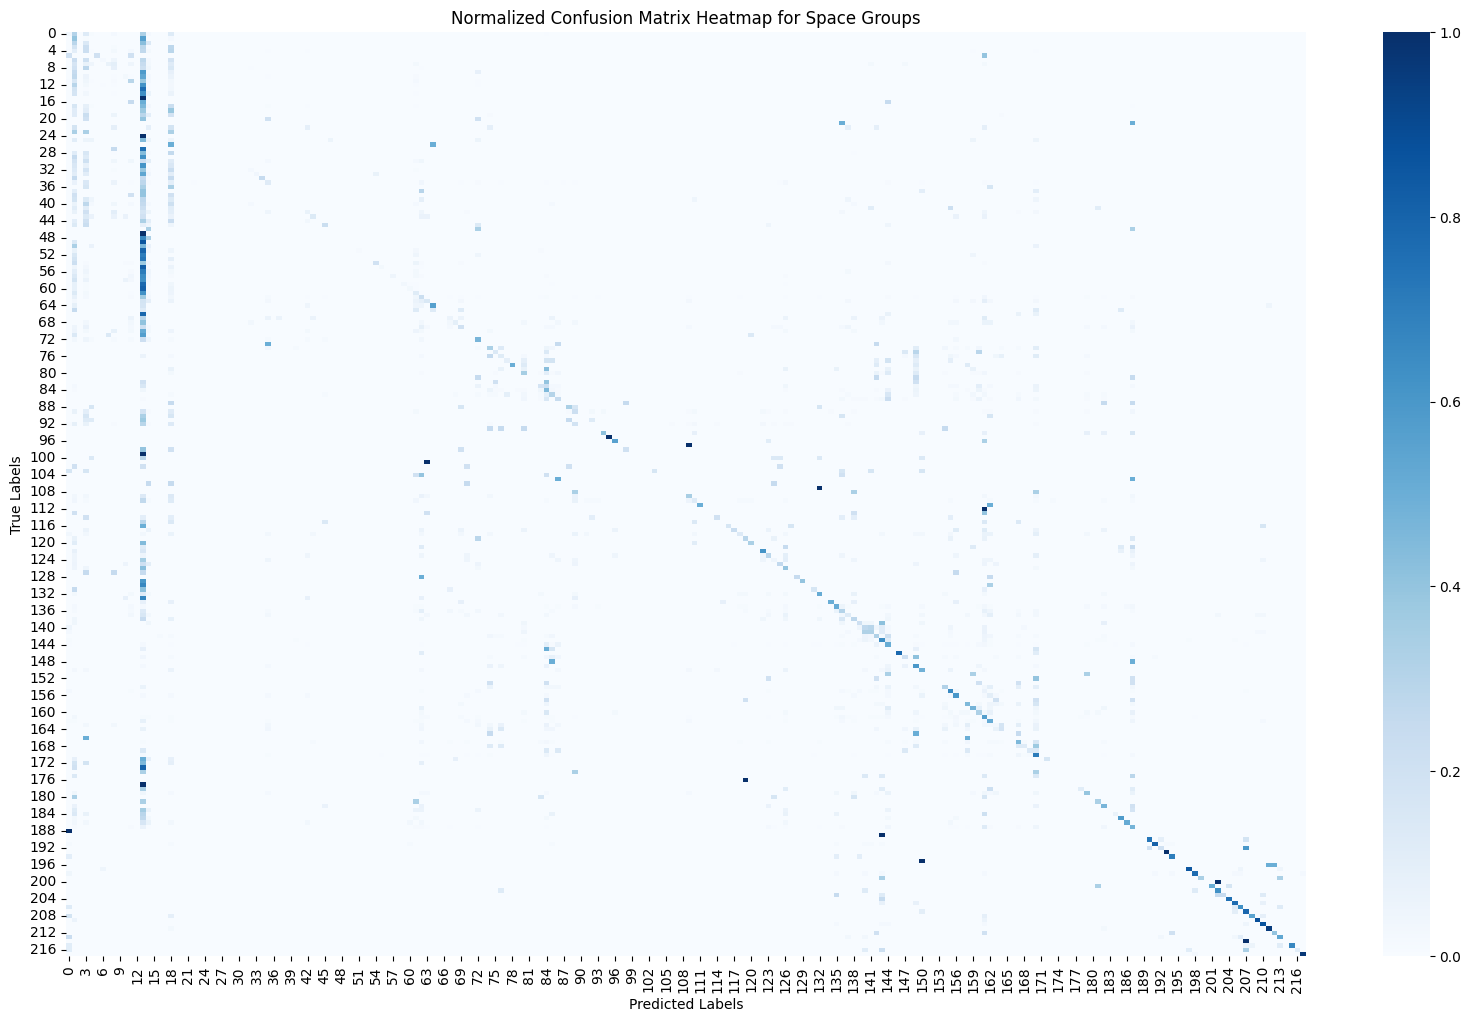

In [34]:
# Compute confusion matrix, normalized to account for class imbalance
conf_matrix = confusion_matrix(all_labels, all_predicted_top1)

# Normalize by row (each true label's sum)
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1, keepdims=True)

# Plot heatmap with better contrast
plt.figure(figsize=(20, 12))
sns.heatmap(conf_matrix_normalized, cmap="Blues", annot=False, fmt=".2f", vmin=0, vmax=1)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Normalized Confusion Matrix Heatmap for Space Groups")
plt.show()

## Model Save

In [31]:
save_path = f"{model_path}{datasource}_{intensity_points}_{twotheta}_{space}_{num_epochs}_{batch_size}_{embed_dim}_{num_heads}{mlp_ratio}_model_checkpoint.pth"
torch.save(model.state_dict(), save_path)